# 1. The data: what's in it, and its hidden problems

**Life Expectancy Predictor · notebook 1 of 7**

Before building anything, we need to understand the raw material. This notebook opens the World Health Organization (WHO) data, explains what each column means, and looks for problems that would quietly mislead a model if we didn't catch them.

**How to read these notebooks.** Each step follows the same pattern:

- **What we are looking for**: the question this step answers.
- **The code and its result**: grey boxes are Python code; the output appears right below. You don't need to read the code to follow along.
- **How to read it**: what the numbers or chart show.
- **What it means**: the conclusion, in plain English.
- **What's next and why**: how this leads to the next step.

## Step 1: Load the data

**What we are looking for.** How big is the dataset, and what does one row describe?

In [1]:
# Setup: find the project folder and load the project's own code and settings.
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "config").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from config_loader import load_config

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
config = load_config(str(ROOT / "config" / "who_life_expectancy.yaml"), base_dir=str(ROOT))

def results(name):
    """Load one of the saved results files in model/."""
    return json.loads((ROOT / "model" / f"{name}.json").read_text(encoding="utf-8"))

print("Project folder:", ROOT.name)

raw = pd.read_csv(config.source_csv)
print(f"{len(raw):,} rows and {raw.shape[1]} columns")
print(f"{raw['Country'].nunique()} countries, years {raw['Year'].min()} to {raw['Year'].max()}")
raw.head(3)

Project folder: nb
2,928 rows and 22 columns
183 countries, years 2000 to 2015


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Haiti,2010,Developing,36.3,682,23,5.76,36.292918,NaN,0,44.2,58,66.0,8.90,66.0,1.9,662.279518,9999617.0,4.0,4.0,0.470,8.6
1,Sierra Leone,2000,Developing,39.0,533,29,3.97,20.395683,NaN,3575,17.2,48,46.0,13.63,44.0,1.2,139.314773,4564297.0,1.3,1.4,0.292,6.7
2,Sierra Leone,2001,Developing,41.0,519,30,4.21,33.346915,NaN,649,17.5,48,38.0,11.83,38.0,1.5,227.779471,4739147.0,1.1,1.2,0.302,7.0


**How to read it.** Each row is one country in one year: for example, Haiti in 2010 or Sierra Leone in 2000. The columns are that country's statistics for that year.

**What it means.** We have 2,928 country-years: 183 countries, each with 16 years (2000-2015). That is a modest dataset by machine-learning standards, and the same country appears 16 times. That second fact matters a great deal later (notebook 3): a fair test must never let the model study a country's 2014 figures and then "predict" its 2015 ones.

**What's next and why.** Next, what the columns actually measure.

## Step 2: What each column measures

**What we are looking for.** Which column are we trying to predict, and which ones will the model use to predict it?

In [2]:
inputs = pd.DataFrame(
    [(p.column, p.label, p.description) for p in config.predictors],
    columns=["Column", "Plain name", "What it measures"],
)
print("Target (what we predict):", config.target_column, "= average life expectancy at birth, in years")
print("Number of inputs the model uses:", len(inputs))
inputs.style.hide(axis="index")

Target (what we predict): Life_Expectancy = average life expectancy at birth, in years
Number of inputs the model uses: 13


Column,Plain name,What it measures
Adult_Mortality,"Adult Mortality (per 1,000 adults)","Probability of dying between ages 15-60, per 1,000 population. Higher = worse."
HIV_AIDS,"HIV/AIDS deaths (per 1,000, ages 0-4)","Deaths per 1,000 live births caused by HIV/AIDS, ages 0-4."
Under-Five_Deaths,"Under-Five Deaths (per 1,000)","Deaths per 1,000 population among children under age 5."
Polio,Polio immunization (%),% of 1-year-olds immunized against polio.
Diphtheria,Diphtheria (DTP3) immunization (%),% of 1-year-olds immunized against diphtheria (DTP3 vaccine).
Hepatitis_B,Hepatitis B immunization (%),% of 1-year-olds immunized against Hepatitis B.
Thinness_10-19_Years,"Thinness, ages 10-19 (%)",% of 10-19 year-olds classified as underweight (thin) for their age.
Alcohol,Alcohol consumption (litres/capita),Liters of pure alcohol consumed per capita (age 15+ population).
Pct_Expenditure,Health expenditure (% of GDP per capita),Health expenditure as a percentage of GDP per capita.
Ttl_Expend,Total govt. health expenditure (% of total govt. expenditure),Total government health spending as a percentage of total government spending.


**How to read it.** The *target* is life expectancy: how many years a baby born that year would live on average. The 13 *inputs* are the statistics the model is allowed to look at. They fall into a few families: deaths (adult mortality, HIV/AIDS, under-five deaths), prevention (immunization rates), nutrition (thinness), spending (health expenditure), and development (income-composition index, schooling).

**What it means.** The source file has more columns than these 13. Five were set aside in the project's configuration because they are unreliable or say the same thing as another column: GDP and population (large gaps and implausible values), infant deaths (nearly identical to under-five deaths), BMI (half its values are physically impossible, see Step 5) and thinness ages 5-9 (nearly identical to ages 10-19). Keeping near-duplicates would not add information; it would only make the model harder to interpret.

**What's next and why.** Before checking quality, a quick look at the thing we are predicting.

## Step 3: What life expectancy looks like

**What we are looking for.** How much does life expectancy vary between countries, and how did it change over the 16 years?

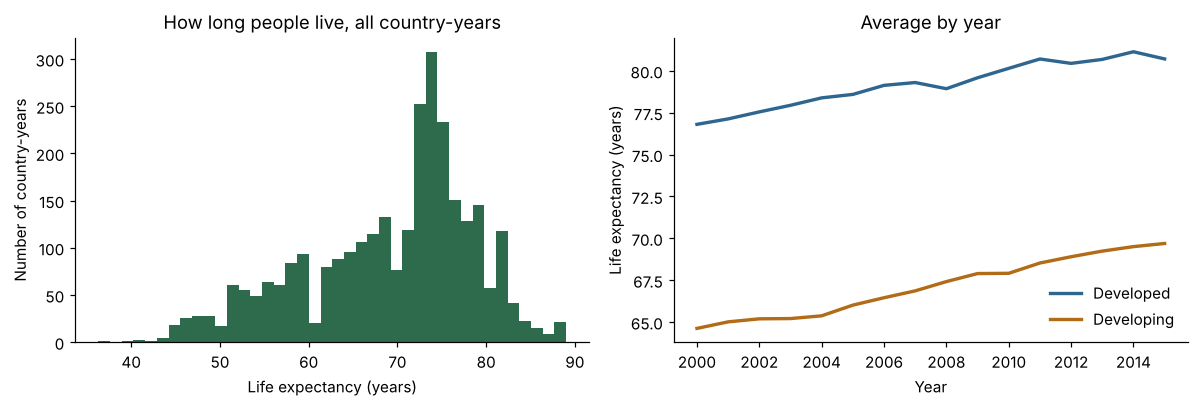

Lowest: 36.3 years. Highest: 89.0 years. Middle value: 72.1 years.


In [3]:
from data_prep import _clean_column_names
df = _clean_column_names(raw, config)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(df["Life_Expectancy"].dropna(), bins=40, color="#2E6A4C")
axes[0].set(title="How long people live, all country-years", xlabel="Life expectancy (years)", ylabel="Number of country-years")
by_year = df.groupby(["Year", "Status"])["Life_Expectancy"].mean().unstack()
axes[1].plot(by_year.index, by_year["Developed"], label="Developed", lw=2.2, color="#2F6690")
axes[1].plot(by_year.index, by_year["Developing"], label="Developing", lw=2.2, color="#B26B16")
axes[1].set(title="Average by year", xlabel="Year", ylabel="Life expectancy (years)")
axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()
print(f"Lowest: {df['Life_Expectancy'].min():.1f} years. Highest: {df['Life_Expectancy'].max():.1f} years. "
      f"Middle value: {df['Life_Expectancy'].median():.1f} years.")

**How to read it.** On the left, each bar counts how many country-years fall in a range of life expectancy; about six in ten sit between 65 and 80 years, with a long tail of much lower values. On the right, the average for developed and developing countries in each year.

**What it means.** The spread is huge: from the 30s to the high 80s. Developing countries gained about 5 years over the period (from 64.6 to 69.7), while developed countries rose from 76.8 to 80.7. The long low tail is where predictions will be hardest, because few countries are there and their circumstances differ a lot (notebook 5).

**What's next and why.** A model can only be as good as its data, so the next two steps check the data's quality.

## Step 4: Missing values, the obvious kind

**What we are looking for.** How many values are simply blank?

In [4]:
blank = (df.isna().mean() * 100).round(1)
blank = blank[blank > 0].sort_values(ascending=False).rename("% blank")
blank.to_frame()

,% blank
Population,22.0
Hepatitis_B,18.9
GDP,15.1
Ttl_Expend,7.7
Alcohol,6.6
Schooling,5.5
Income_Comp_Of_Resources,5.5
BMI,1.1
Thinness_10-19_Years,1.1
Thinness_5-9_Years,1.1


**How to read it.** Each row is a column, with the share of its values that are empty in the file.

**What it means.** Some gaps are large (population 22%, hepatitis B 19%, GDP 15%), which is one reason population and GDP were set aside. Most other columns look nearly complete. But "looks complete" can be misleading, as the next step shows.

**What's next and why.** Some columns hide their gaps by filling them with a number.

## Step 5: Missing values, the hidden kind

**What we are looking for.** Values that are present but cannot be true, such as a country with zero infant deaths in a year, or an adult BMI of 1. These are placeholders for "not reported", and a model would treat them as real.

In [5]:
checks = pd.DataFrame({
    "Rows where the value is exactly 0": {
        "Infant deaths": int((df["Infant_Deaths"] == 0).sum()),
        "Under-five deaths": int((df["Under-Five_Deaths"] == 0).sum()),
        "Health expenditure (% of GDP)": int((df["Pct_Expenditure"] == 0).sum()),
    }
})
print(checks.to_string())
print()
print("Health expenditure is 0 for", int((df.loc[df["Year"] == 2015, "Pct_Expenditure"] == 0).sum()),
      "of 183 countries in 2015.")
bmi_bad = ~df["BMI"].between(10, 50)
print(f"Average adult BMI outside 10-50 (physically implausible): {bmi_bad.sum():,} of {len(df):,} rows ({bmi_bad.mean():.0%}).")

                               Rows where the value is exactly 0
Infant deaths                                                838
Under-five deaths                                            775
Health expenditure (% of GDP)                                606

Health expenditure is 0 for 181 of 183 countries in 2015.
Average adult BMI outside 10-50 (physically implausible): 1,446 of 2,928 rows (49%).


**How to read it.** The first table counts values of exactly zero in columns where zero is not believable. The last two lines show the clearest cases: 181 of the 183 countries report zero health spending in 2015, and half the BMI values are outside the range a population average could take.

**What it means.** These are not real zeros; they are gaps wearing a disguise. A plain blank-value check (Step 4) reports them as complete, so they are easy to miss. If we left them in, the model would learn, for example, that some countries spend nothing on health. The cleaning step (notebook 2) turns each of these into an honest gap before filling it. BMI is so unreliable that it is left out of the model entirely.

**What's next and why.** One more problem is in the labels, not the numbers.

## Step 6: A labelling problem

**What we are looking for.** The data tags every country as "Developed" or "Developing". Are the tags right?

In [6]:
summary = df.groupby("Country").agg(status=("Status", "first"),
                                    life_expectancy=("Life_Expectancy", "mean"),
                                    income_index=("Income_Comp_Of_Resources", "mean"))
suspects = ["Canada", "Finland", "France", "Greece", "Israel", "Republic of Korea"]
summary.loc[suspects].round(2)

,status,life_expectancy,income_index
Country,,,
Canada,Developing,81.69,0.89
Finland,Developing,80.71,0.87
France,Developing,82.22,0.87
Greece,Developing,81.22,0.84
Israel,Developing,81.30,0.87
Republic of Korea,Developing,80.49,NaN


**How to read it.** Six countries that are advanced economies by any standard classification, with high life expectancy and a high income index, are tagged "Developing". (Korea's income index is blank in the file, another gap.)

**What it means.** The status label is not used by the model (it is not one of the 13 inputs), so this does not affect predictions. It does matter when results are compared between developed and developing countries (notebook 6), where these six are moved to the right group first and the effect of doing so is shown.

**What's next and why.** Notebook 2 cleans the data: it turns the hidden gaps into real gaps, fills them sensibly, and tames extreme values, without letting the test data leak into the process.

## Summary

| What we checked | What we found | What the project does about it |
| --- | --- | --- |
| Size and shape | 2,928 country-years, 183 countries, 16 years each | The fair test holds out whole countries (notebook 3) |
| Columns | 13 usable inputs; 5 unreliable or duplicate columns | Those 5 are left out |
| Obvious gaps | Large in population, hepatitis B, GDP | Gaps are filled from each country's other years (notebook 2) |
| Hidden gaps | Zeros that mean "not reported" (606 in health spending, including 181 of 183 countries in 2015); impossible BMI values | Zeros are turned into gaps before filling; BMI is left out |
| Labels | Six advanced economies tagged "Developing" | Corrected only where groups are compared (notebook 6) |